# Etapa 1 — Baseline clásico: Factorización Matricial (SVD)

Este notebook implementa la primera etapa del plan: un modelo de referencia clásico basado en SVD sobre MovieLens, con las métricas base que se van a reutilizar en todas las etapas siguientes (RMSE, MAE, precision@k, recall@k).

## 1. Setup: instalación y montaje de Drive

In [ ]:
# Montar Google Drive para persistir datos y resultados entre sesiones
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/tesis-recsys'
for sub in ['data', 'notebooks', 'models', 'results']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)
print('Estructura de carpetas lista en', PROJECT_DIR)

Mounted at /content/drive
Estructura de carpetas lista en /content/drive/MyDrive/tesis-recsys


In [ ]:
!pip install -q scikit-surprise pandas numpy scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 83.0 MB/s eta 0:00:00


## 2. Descarga y carga de MovieLens (ml-latest-small)

In [ ]:
import os
import ssl
import urllib.request
import zipfile

DATA_DIR = f'{PROJECT_DIR}/data'
url = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
zip_path = f'{DATA_DIR}/ml-latest-small.zip'

if not os.path.exists(f'{DATA_DIR}/ml-latest-small/ratings.csv'):
  # Desactivar la verificación del certificado SSL
  context = ssl._create_unverified_context()

  with urllib.request.urlopen(url, context=context) as response, open(
      zip_path, 'wb'
  ) as out_file:
    out_file.write(response.read())

  with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(DATA_DIR)
  print('Dataset descargado y extraído.')
else:
  print('Dataset ya presente, se omite la descarga.')

Dataset descargado y extraído.


In [ ]:
import pandas as pd

ratings = pd.read_csv(f'{DATA_DIR}/ml-latest-small/ratings.csv')
movies = pd.read_csv(f'{DATA_DIR}/ml-latest-small/movies.csv')

print(ratings.shape, movies.shape)
ratings.head()

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 3. Análisis exploratorio básico

Esto sirve para tener una primera noción de la escasez de datos (sparsity) y del long-tail de popularidad, que después vamos a usar para medir sesgo.

In [ ]:
n_users = ratings['userId'].nunique()
n_items = ratings['movieId'].nunique()
n_ratings = len(ratings)
sparsity = 1 - (n_ratings / (n_users * n_items))

print(f'Usuarios: {n_users}')
print(f'Películas: {n_items}')
print(f'Ratings: {n_ratings}')
print(f'Sparsity: {sparsity:.4%}')

Usuarios: 610
Películas: 9724
Ratings: 100836
Sparsity: 98.3000%


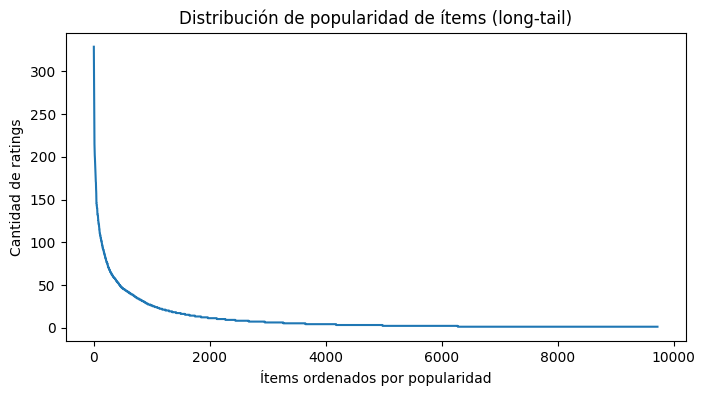

In [ ]:
import matplotlib.pyplot as plt

item_counts = ratings['movieId'].value_counts()

plt.figure(figsize=(8, 4))
plt.plot(range(len(item_counts)), item_counts.values)
plt.title('Distribución de popularidad de ítems (long-tail)')
plt.xlabel('Ítems ordenados por popularidad')
plt.ylabel('Cantidad de ratings')
plt.show()

# Guardamos esto porque lo vamos a necesitar más adelante para medir sesgo de popularidad
item_counts.to_csv(f'{PROJECT_DIR}/results/item_popularity.csv')

## 4. Entrenamiento del modelo SVD

In [ ]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split, cross_validate
from surprise import accuracy

reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

model = SVD(n_factors=100, n_epochs=20, random_state=42)
model.fit(trainset)

predictions = model.test(testset)
print('RMSE:', accuracy.rmse(predictions))
print('MAE:', accuracy.mae(predictions))

RMSE: 0.8807
RMSE: 0.8807462819979623
MAE:  0.6766
MAE: 0.6765729095860605


In [ ]:
# Cross-validation de 5 folds sobre todo el dataset, para tener una estimación más robusta
cv_results = cross_validate(SVD(n_factors=100, n_epochs=20, random_state=42), data, measures=['RMSE', 'MAE'], cv=5, verbose=True)

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8820  0.8634  0.8732  0.8786  0.8731  0.8741  0.0063  
MAE (testset)     0.6766  0.6648  0.6725  0.6737  0.6714  0.6718  0.0039  
Fit time          1.05    1.46    1.50    1.07    1.08    1.23    0.20    
Test time         0.22    0.17    0.17    0.10    0.11    0.16    0.04    


## 5. Métricas de recomendación: precision@k y recall@k

Surprise no las trae implementadas, así que las armamos a mano. Estas mismas funciones se van a reutilizar en las etapas siguientes (NCF, two-stage, generativo) para que la comparación final sea justa.

In [ ]:
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=3.5):
    """Devuelve precision@k y recall@k promedio sobre todos los usuarios."""
    user_est_true = defaultdict(list)
    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions, recalls = {}, {}
    for uid, user_ratings in user_est_true.items():
        user_ratings.sort(key=lambda x: x[0], reverse=True)
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])
        n_rel_and_rec_k = sum(
            ((true_r >= threshold) and (est >= threshold))
            for (est, true_r) in user_ratings[:k]
        )
        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    avg_precision = sum(prec for prec in precisions.values()) / len(precisions)
    avg_recall = sum(rec for rec in recalls.values()) / len(recalls)
    return avg_precision, avg_recall

precision, recall = precision_recall_at_k(predictions, k=10, threshold=3.5)
print(f'Precision@10: {precision:.4f}')
print(f'Recall@10: {recall:.4f}')

Precision@10: 0.7446
Recall@10: 0.5086


## 6. Guardar resultados

Guardamos las métricas en un CSV que va a ir acumulando resultados de cada etapa, para armar la tabla comparativa final de la tesis.

In [ ]:
import csv
from datetime import datetime

results_path = f'{PROJECT_DIR}/results/comparativa_modelos.csv'
row = {
    'modelo': 'SVD (baseline)',
    'rmse': accuracy.rmse(predictions, verbose=False),
    'mae': accuracy.mae(predictions, verbose=False),
    'precision_at_10': precision,
    'recall_at_10': recall,
    'fecha': datetime.now().isoformat(timespec='seconds'),
}

file_exists = os.path.exists(results_path)
with open(results_path, 'a', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=row.keys())
    if not file_exists:
        writer.writeheader()
    writer.writerow(row)

print('Resultado guardado en', results_path)
row

Resultado guardado en /content/drive/MyDrive/tesis-recsys/results/comparativa_modelos.csv


{'modelo': 'SVD (baseline)',
 'rmse': np.float64(0.8807462819979623),
 'mae': np.float64(0.6765729095860605),
 'precision_at_10': np.float64(0.7446291959406721),
 'recall_at_10': np.float64(0.5086160453516007),
 'fecha': '2026-09-12T20:00:25'}